# WP08 — B0_frequency_reference_v1 keşifsel referans kontrolü

**Bu karşılaştırma B1/B2 sonuçları görüldükten sonra kararlaştırıldı; keşifseldir.** Kabul edilen B1=0,6556 ve B2=0,6262 ana ortak drug-AP değerleri korunur. Eski model, skor, split, C, seed ve hedef sözlüğü değiştirilmedi.

B0 yalnız train ilaçlarında gözlenen PT kayıt sayısı / tanımlı train ilaç sayısıdır. Kimya, protein, PPI, ATC veya test sıklığı kullanmaz. Skor klinik yan etki olasılığı değildir. Unknown doğrulanmış biyolojik negatif değildir. Tek formül, smoothing/dönüşüm/tuning yok; B0 sonuçları hesaplanmadan bu ekin politikası kaydedildi. Bu, B1/B2 görülmeden yapılmış confirmatory preregistration anlamına gelmez.

,version,exploratory_after_B1_B2_results,accepted_original_primary_paired_AP,score_formula,smoothing,score_transform,hyperparameter_search,intrinsic_eligibility,Methenamine,targets,no_new_target_selection,...,bootstrap_reps,bootstrap_min_valid,seed,bootstrap_seed,bootstrap_unit,CI_scope,PPI_ATC_chemistry_sequence_values_read,B1_B2_refit_or_retuning,WP08_closed,WP09_started,semantics
0,B0_frequency_reference_v1,True,"{'B1': 0.6556, 'B2': 0.6262}",count(unique train drugs with observed PT record) / number of defined train drugs,None,identity,False,"all 62 inventory IDs; only a population reference, not personalized prediction",B0 population reference allowed; B1/B2 abstention remains unchanged; excluded from matched compa...,frozen cohort train PT dictionary; matched evaluations use EXACT existing B1/B2 scored target keys,True,...,1000,800,20261106,20261106+9000+protocol_index (same frozen baseline draws),locked structural group; paired identical draws,conditional on fixed OOF models and frequency estimates; no full retraining bootstrap,False,False,False,False,Exploratory train-frequency observed-record ranking reference; unknown is NOT verified negative;...


,context,protocol,outer_fold,inner_fold,reference,train_drugs,semantics
0,primary_o01_final,primary,1,0,B0_all_train,49,Exploratory train-frequency observed-record ranking reference; unknown is NOT verified negative;...
1,primary_o01_final,primary,1,0,B0_like_B1,43,Exploratory train-frequency observed-record ranking reference; unknown is NOT verified negative;...
2,primary_o01_final,primary,1,0,B0_like_B2,48,Exploratory train-frequency observed-record ranking reference; unknown is NOT verified negative;...
12,primary_o02_final,primary,2,0,B0_all_train,49,Exploratory train-frequency observed-record ranking reference; unknown is NOT verified negative;...
13,primary_o02_final,primary,2,0,B0_like_B1,43,Exploratory train-frequency observed-record ranking reference; unknown is NOT verified negative;...
14,primary_o02_final,primary,2,0,B0_like_B2,48,Exploratory train-frequency observed-record ranking reference; unknown is NOT verified negative;...
24,primary_o03_final,primary,3,0,B0_all_train,50,Exploratory train-frequency observed-record ranking reference; unknown is NOT verified negative;...
25,primary_o03_final,primary,3,0,B0_like_B1,43,Exploratory train-frequency observed-record ranking reference; unknown is NOT verified negative;...
26,primary_o03_final,primary,3,0,B0_like_B2,50,Exploratory train-frequency observed-record ranking reference; unknown is NOT verified negative;...
36,primary_o04_final,primary,4,0,B0_all_train,50,Exploratory train-frequency observed-record ranking reference; unknown is NOT verified negative;...


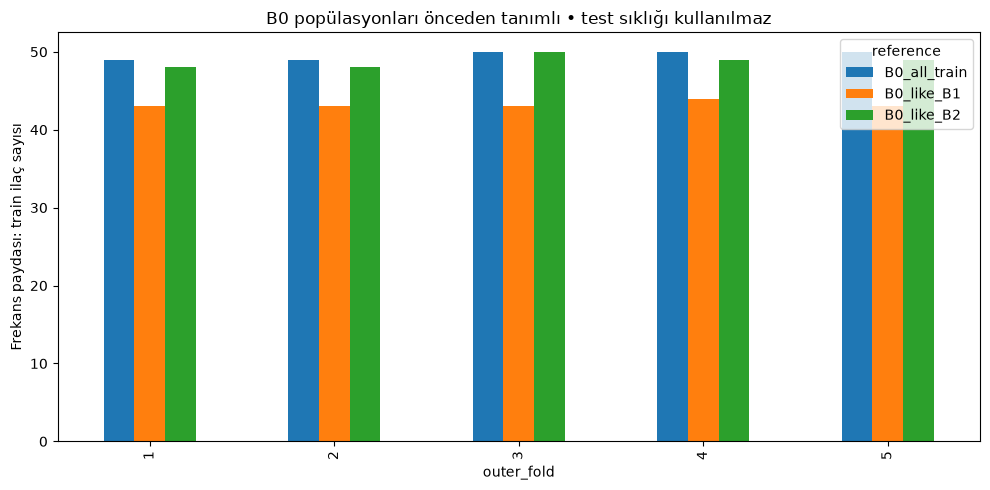

In [1]:
from pathlib import Path
import json,numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():ROOT=ROOT.parent
QA=ROOT/'reports/qa/WP08/B0_frequency_reference_v1';FIG=ROOT/'reports/figures/WP08/B0_frequency_reference_v1';FIG.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_rows',180);pd.set_option('display.max_columns',22);pd.set_option('display.max_colwidth',100)
def read(n):return pd.read_csv(QA/n,keep_default_na=False)
policy=json.loads((QA/'policy_before_B0_results.json').read_text(encoding='utf-8'))
display(pd.DataFrame([policy]).drop(columns=['train_populations','main_comparisons','scope']))
pop=read('train_population_sizes.csv');display(pop[pop.inner_fold.eq(0)])
fig,ax=plt.subplots(figsize=(10,5));p=pop[pop.protocol.eq('primary')&pop.inner_fold.eq(0)].pivot(index='outer_fold',columns='reference',values='train_drugs');p.plot.bar(ax=ax);ax.set(ylabel='Frekans paydası: train ilaç sayısı',title='B0 popülasyonları önceden tanımlı • test sıklığı kullanılmaz');plt.tight_layout();plt.savefig(FIG/'01_train_population_denominators.png',dpi=160);plt.show()

**Yorum:** B0_all_train bütün train ilaçlarını, B0_like_B1/B0_like_B2 ilgili modelin input-uygun train ilaçlarını kullanır. İkinci ve üçüncü popülasyon yalnız eşleştirilmiş referans tasarımı için frozen ID/eligibility bilgisine dayanır; sayısal biyolojik değer okunmaz. Böylece farklı train paydaları gizlenmez ve iyi sonuç veren payda sonradan seçilmez.

## 1. Gerçek train sıklığı ve girdisiz ilaç politikası

In [2]:
frequency=read('train_frequency_estimates.csv');example=frequency[frequency.context.eq('primary_o01_final')&frequency.reference.eq('B0_like_B1')].sort_values('frequency_score',ascending=False)
display(example.head(15).drop(columns=['semantics']))
display(read('train_population_ids.csv').query("context == 'primary_o01_final'").head(15).drop(columns=['semantics']))
status=read('B0_status_all62.csv');display(status[status.drug_id.eq('DB06799')].drop(columns=['semantics']))
coverage=read('coverage_and_positive_unknown.csv');display(coverage[coverage.scope.eq('B0_all62_reference_ONLY')].drop(columns=['semantics']))

,context,protocol,outer_fold,inner_fold,reference,pt_cui,observed_train_drugs,train_drugs,frequency_score
338,primary_o01_final,primary,1,0,B0_like_B1,C0027497,42,43,0.976744
295,primary_o01_final,primary,1,0,B0_like_B1,C0015230,41,43,0.953488
396,primary_o01_final,primary,1,0,B0_like_B1,C0042963,40,43,0.930233
281,primary_o01_final,primary,1,0,B0_like_B1,C0011991,39,43,0.906977
275,primary_o01_final,primary,1,0,B0_like_B1,C0011603,38,43,0.883721
243,primary_o01_final,primary,1,0,B0_like_B1,C0002792,38,43,0.883721
315,primary_o01_final,primary,1,0,B0_like_B1,C0020517,37,43,0.860465
358,primary_o01_final,primary,1,0,B0_like_B1,C0033774,36,43,0.837209
391,primary_o01_final,primary,1,0,B0_like_B1,C0042109,36,43,0.837209
378,primary_o01_final,primary,1,0,B0_like_B1,C0040034,35,43,0.813953


,context,reference,train_drug_id
0,primary_o01_final,B0_all_train,DB00199
1,primary_o01_final,B0_all_train,DB00207
2,primary_o01_final,B0_all_train,DB00259
3,primary_o01_final,B0_all_train,DB00301
4,primary_o01_final,B0_all_train,DB00303
5,primary_o01_final,B0_all_train,DB00319
6,primary_o01_final,B0_all_train,DB00359
7,primary_o01_final,B0_all_train,DB00415
8,primary_o01_final,B0_all_train,DB00417
9,primary_o01_final,B0_all_train,DB00440


,context,protocol,outer_fold,inner_fold,reference,drug_id,status,biological_input_required,inventory_retained
89,primary_o03_final,primary,3,0,B0_all_train,DB06799,POPULATION_FREQUENCY_REFERENCE_NOT_PERSONALIZED,False,True
101,primary_o03_final,primary,3,0,B0_like_B1,DB06799,POPULATION_FREQUENCY_REFERENCE_NOT_PERSONALIZED,False,True
113,primary_o03_final,primary,3,0,B0_like_B2,DB06799,POPULATION_FREQUENCY_REFERENCE_NOT_PERSONALIZED,False,True
311,stress_o04_final,stress,4,0,B0_all_train,DB06799,POPULATION_FREQUENCY_REFERENCE_NOT_PERSONALIZED,False,True
323,stress_o04_final,stress,4,0,B0_like_B1,DB06799,POPULATION_FREQUENCY_REFERENCE_NOT_PERSONALIZED,False,True
335,stress_o04_final,stress,4,0,B0_like_B2,DB06799,POPULATION_FREQUENCY_REFERENCE_NOT_PERSONALIZED,False,True


,protocol,scope,model,exploratory_after_baseline,inventory_drugs,scored_drugs,drug_AP_evaluable,scored_pairs,observed_positive_scored,unknown_scored_NOT_verified_negative,source_positive_for_scored_drugs,out_of_scored_vocab_positive,class_AUROC_evaluable
16,primary,B0_all62_reference_ONLY,B0_all_train,True,62,62,62,18334,4596,13738,6416,1820,294
33,stress,B0_all62_reference_ONLY,B0_all_train,True,62,62,62,18286,4590,13696,6416,1826,301


**Yorum:** B0 aynı outer fold içinde aynı PT için bütün test ilaçlarına aynı popülasyon skorunu verir; bireye özgü ayrım yapmaz. Biyolojik input gerektirmediği için Methenamine dahil 62 ilaçta bu referans hesaplanabilir. Bu durum B1/B2'nin Methenamine abstention'ını iptal etmez. Paired kıyasta B0 tam olarak aynı eski model ilaç/target anahtarlarına kısıtlanır; 62'lik referans ayrı ve doğrudan kıyaslanmayan kapsamdır. 0/1 sıklıklar yalnız train kayıt oranıdır, gerçek yokluk veya klinik olasılık değildir.

## 2. B1/B2, kayıt sıklığını geçiyor mu?

,protocol,scope,model,exploratory_after_baseline,metric,estimate,CI95_low,CI95_high,valid_bootstrap_replicates,CI_NA_reason
30,primary,paired54,B1,True,drug_macro_AP,0.655642,0.613111,0.692041,1000,
34,primary,paired54,B1,True,class_macro_AUROC,0.481439,0.428299,0.533029,1000,
35,primary,paired54,B2,True,drug_macro_AP,0.626239,0.579200,0.670094,1000,
39,primary,paired54,B2,True,class_macro_AUROC,0.543061,0.499882,0.589697,1000,
40,primary,paired54,B0_all_train,True,drug_macro_AP,0.646507,0.603990,0.685192,1000,
44,primary,paired54,B0_all_train,True,class_macro_AUROC,0.328927,0.302062,0.362025,1000,
45,primary,paired54,B0_like_B1,True,drug_macro_AP,0.643787,0.602130,0.681983,1000,
49,primary,paired54,B0_like_B1,True,class_macro_AUROC,0.318814,0.295338,0.350019,1000,
50,primary,paired54,B0_like_B2,True,drug_macro_AP,0.646604,0.604371,0.685339,1000,
54,primary,paired54,B0_like_B2,True,class_macro_AUROC,0.328135,0.301820,0.361643,1000,


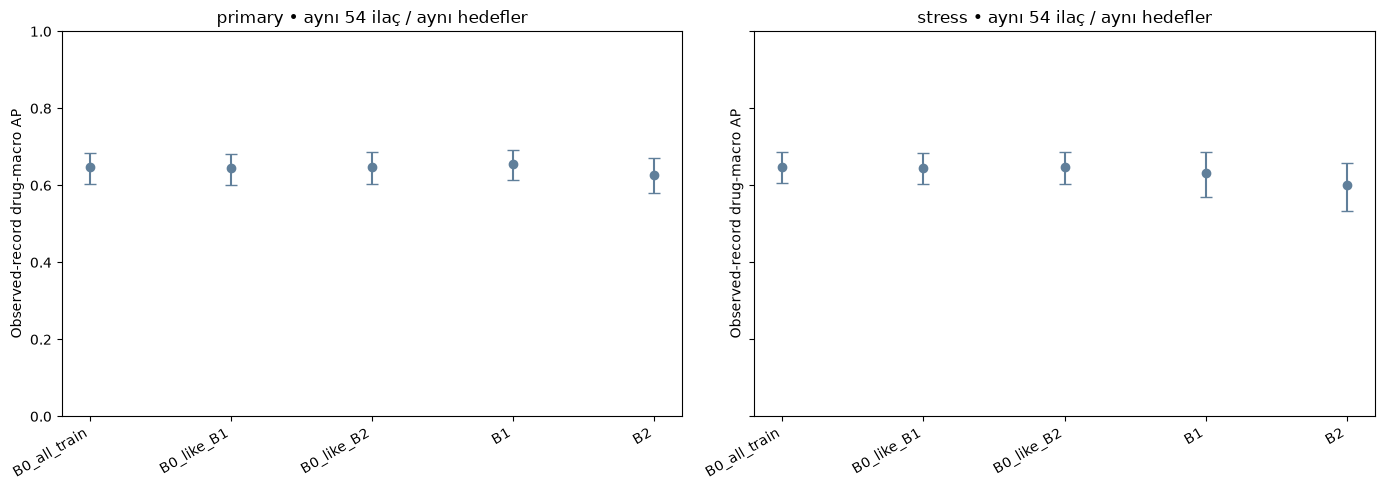

In [3]:
metrics=read('metrics_with_group_CI.csv');delta=read('paired_differences_group_CI.csv')
paired=metrics[metrics.scope.eq('paired54')];display(paired[paired.metric.isin(['drug_macro_AP','class_macro_AUROC'])].drop(columns=['semantics','CI_scope']))
order=['B0_all_train','B0_like_B1','B0_like_B2','B1','B2']
fig,axs=plt.subplots(1,2,figsize=(14,5),sharey=True)
for ax,protocol in zip(axs,['primary','stress']):
    f=paired[paired.protocol.eq(protocol)&paired.metric.eq('drug_macro_AP')].set_index('model').loc[order]
    xx=np.arange(len(f));ax.errorbar(xx,f.estimate,yerr=np.vstack([f.estimate-f.CI95_low,f.CI95_high-f.estimate]).astype(float),fmt='o',capsize=4,color='#607f9a');ax.set_xticks(xx,order,rotation=30,ha='right');ax.set(ylim=(0,1),ylabel='Observed-record drug-macro AP',title=protocol+' • aynı 54 ilaç / aynı hedefler')
plt.tight_layout();plt.savefig(FIG/'02_matched_drug_AP.png',dpi=160);plt.show()

**Yorum:** Ana ortak kapsamda B1 0,6556, B0_like_B1 0,6438; B2 0,6262, B0_like_B2 0,6466. B1'in küçük nokta avantajı tek başına üstünlük kanıtı değildir. B0 sonuçlarının B1'e yakın olması, yalnız sıklık sıralamasının güçlü bir referans olduğunu gösterir. “Başarının yüzde kaçı frekanstan kaynaklandı?” şeklinde nedensel veya açıklanan-varyans yüzdesi bu AP değerlerinden hesaplanamaz; doğru nicelik eşleştirilmiş ek AP farkıdır.

## 3. Aynı grup çekimleriyle model − B0 farkları

,protocol,scope,first,reference,metric,first_minus_reference,CI95_low,CI95_high,valid_bootstrap_replicates,CI_NA_reason,exploratory_after_baseline
20,primary,paired54,B1,B0_like_B1,drug_macro_AP,0.011855,-0.002096,0.027365,1000,,True
25,primary,paired54,B1,B0_all_train,drug_macro_AP,0.009135,-0.005851,0.025493,1000,,True
30,primary,paired54,B2,B0_like_B2,drug_macro_AP,-0.020365,-0.043756,0.003183,1000,,True
35,primary,paired54,B2,B0_all_train,drug_macro_AP,-0.020268,-0.044365,0.003162,1000,,True
90,stress,paired54,B1,B0_like_B1,drug_macro_AP,-0.012122,-0.041223,0.011061,1000,,True
95,stress,paired54,B1,B0_all_train,drug_macro_AP,-0.015286,-0.045620,0.009439,1000,,True
100,stress,paired54,B2,B0_like_B2,drug_macro_AP,-0.046864,-0.076893,-0.017625,1000,,True
105,stress,paired54,B2,B0_all_train,drug_macro_AP,-0.047461,-0.078105,-0.017649,1000,,True


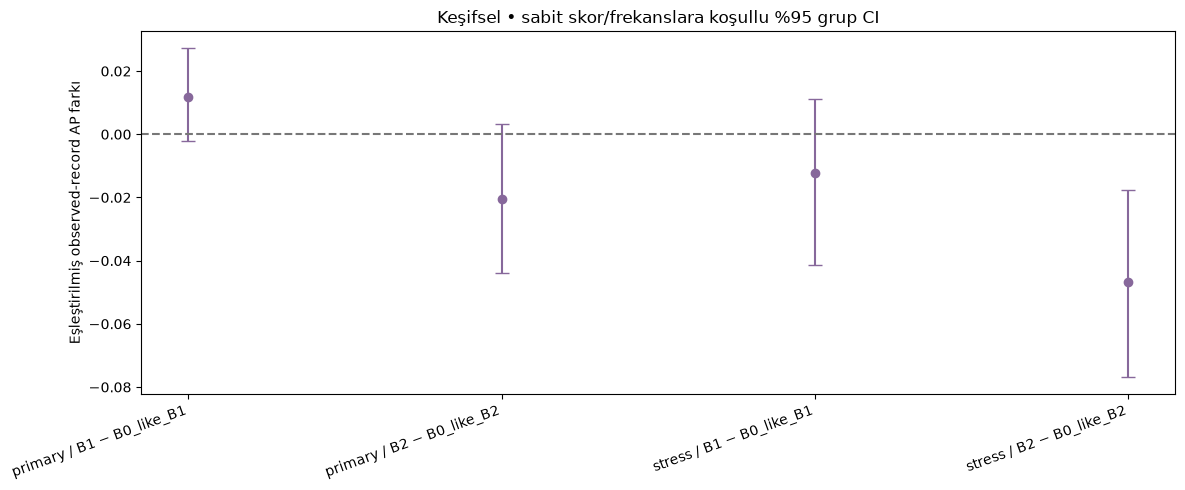

In [4]:
d=delta[delta.scope.eq('paired54')&delta.metric.eq('drug_macro_AP')&delta.reference.str.startswith('B0')];display(d.drop(columns=['semantics','CI_scope']))
fig,ax=plt.subplots(figsize=(12,5));f=d[((d['first']=='B1')&(d.reference=='B0_like_B1'))|((d['first']=='B2')&(d.reference=='B0_like_B2'))].copy();xx=np.arange(len(f))
ax.errorbar(xx,f.first_minus_reference,yerr=np.vstack([f.first_minus_reference-f.CI95_low,f.CI95_high-f.first_minus_reference]).astype(float),fmt='o',capsize=5,color='#87689b');ax.axhline(0,ls='--',color='#777');ax.set_xticks(xx,f.protocol+' / '+f['first']+' − '+f.reference,rotation=20,ha='right');ax.set(ylabel='Eşleştirilmiş observed-record AP farkı',title='Keşifsel • sabit skor/frekanslara koşullu %95 grup CI');plt.tight_layout();plt.savefig(FIG/'03_model_minus_frequency_group_CI.png',dpi=160);plt.show()

**Yorum:** Ana B1−B0_like_B1 ≈+0,0119; %95 koşullu CI yaklaşık [−0,0021,+0,0274]. Ana B2−B0_like_B2 ≈−0,0204; CI yaklaşık [−0,0438,+0,0032]. İkisi de sıfırı içerir. Stres protokolünde B2'nin farkı daha düşüktür ve koşullu aralık sıfırın altındadır; bu da keşifsel, sabit OOF koşullu sonuçtur. Çoklu keşifsel kıyasları confirmatory test gibi sunmuyoruz. B1/B2'ye yeniden C araması veya eğitim yapılmadı.

Bootstrap 1000 kez kilitli yapısal grupları birlikte örnekler; aynı çekimler bütün karşılaştırılan skor panellerinde kullanılır. Pair/fold bağımsızlığı varsayılmaz. Bu CI tüm tekrar eğitim belirsizliği veya bağımsız dış doğrulama değildir.

## 4. Drug-AP ve class-AUROC neden farklı yönlere gidebilir?

,protocol,scope,model,exploratory_after_baseline,outer_fold,metric,estimate,scored_drugs,class_AUROC_evaluable
0,primary,paired54,B1,True,1,class_macro_AUROC,0.581708,11,208
1,primary,paired54,B1,True,2,class_macro_AUROC,0.591015,11,207
2,primary,paired54,B1,True,3,class_macro_AUROC,0.584384,11,219
3,primary,paired54,B1,True,4,class_macro_AUROC,0.450175,10,216
4,primary,paired54,B1,True,5,class_macro_AUROC,0.549094,11,204
5,primary,paired54,B2,True,1,class_macro_AUROC,0.631399,11,208
6,primary,paired54,B2,True,2,class_macro_AUROC,0.604641,11,207
7,primary,paired54,B2,True,3,class_macro_AUROC,0.580496,11,219
8,primary,paired54,B2,True,4,class_macro_AUROC,0.514862,10,216
9,primary,paired54,B2,True,5,class_macro_AUROC,0.526404,11,204


,protocol,model,descriptive_mean_of_5_fold_class_AUROC,min_fold,max_fold,CI_status
0,primary,B0_all_train,0.500000,0.500000,0.500000,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
1,primary,B0_like_B1,0.500000,0.500000,0.500000,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
2,primary,B0_like_B2,0.500000,0.500000,0.500000,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
3,primary,B1,0.551275,0.450175,0.591015,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
4,primary,B2,0.571560,0.514862,0.631399,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
5,stress,B0_all_train,0.500000,0.500000,0.500000,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
6,stress,B0_like_B1,0.500000,0.500000,0.500000,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
7,stress,B0_like_B2,0.500000,0.500000,0.500000,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
8,stress,B1,0.572165,0.540152,0.609805,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
9,stress,B2,0.562478,0.505352,0.628856,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement


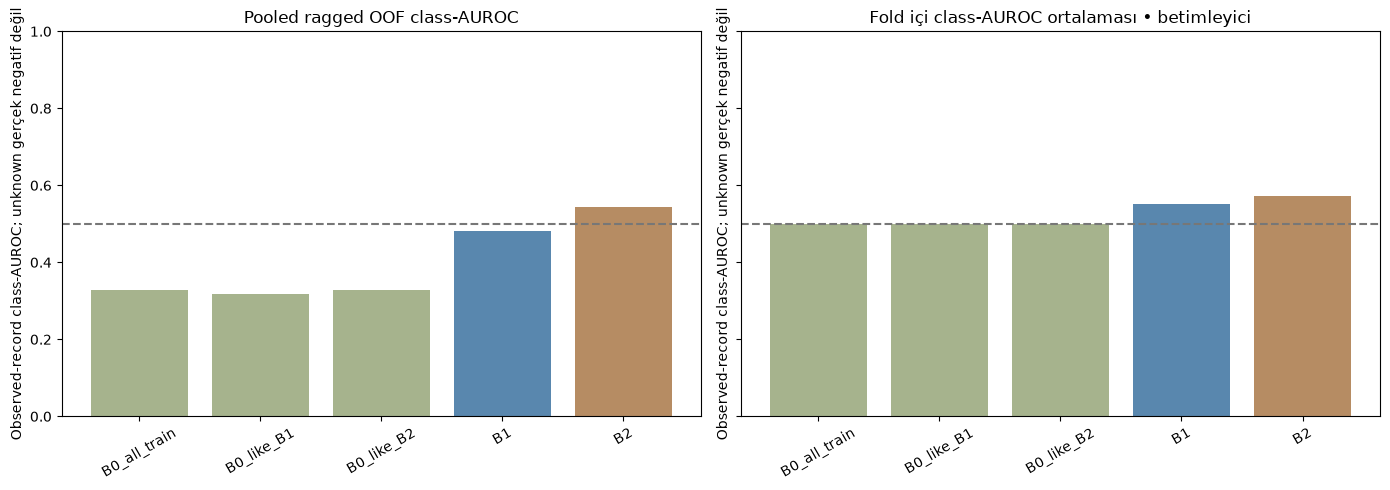

In [5]:
within=read('within_fold_class_AUROC_diagnostic.csv');mean=read('within_fold_AUROC_descriptive_mean.csv');display(within[within.protocol.eq('primary')].drop(columns=['semantics']));display(mean.drop(columns=['semantics']))
pooled=paired[paired.protocol.eq('primary')&paired.metric.eq('class_macro_AUROC')].set_index('model').loc[order]
local=mean[mean.protocol.eq('primary')].set_index('model').loc[order]
fig,axs=plt.subplots(1,2,figsize=(14,5),sharey=True)
axs[0].bar(order,pooled.estimate,color=['#a6b38d']*3+['#5987ae','#b68c63']);axs[0].set_title('Pooled ragged OOF class-AUROC')
axs[1].bar(order,local.descriptive_mean_of_5_fold_class_AUROC,color=['#a6b38d']*3+['#5987ae','#b68c63']);axs[1].set_title('Fold içi class-AUROC ortalaması • betimleyici')
for ax in axs:ax.axhline(.5,color='#777',ls='--');ax.tick_params(axis='x',rotation=30);ax.set(ylim=(0,1),ylabel='Observed-record class-AUROC; unknown gerçek negatif değil')
plt.tight_layout();plt.savefig(FIG/'04_pooled_vs_within_fold_class_AUROC.png',dpi=160);plt.show()

**Yorum:** Drug-AP, bir ilacın PT'lerini birbirine göre sıralar; class-AUROC aynı PT'de farklı ilaçları ayırt etmeyi sorar. Sık PT'ler herkeste üstte olduğunda kişiselleştirme olmadan drug-AP yüksek olabilir. B2 bazı sınıf içi ayrımları geliştirirken PT'ler arası sıralamayı zayıflatabilir; tek bir “daha iyi” ölçü gibi yorumlanmaz.

**B0 için kritik kontrol:** Fold içinde bir PT'nin skoru sabittir; iki outcome varsa AUROC tam 0,5 olmalıdır ve doğrulandı. Pooled OOF'ta skorlar foldların train sıklığıyla değişir; testte kaydı daha yoğun olan bir foldun tamamlayıcı train sıklığı daha düşük olabilir. Bu nedenle pooled B0 class-AUROC≈0,32 iken fold içi değer 0,5'tir. Bunu B0'ın “ters klinik tahmini” veya bütün B1/B2 sınıf ayrımının kazanımı gibi yorumlamamak gerekir. Yeni fold-içi tablo açıklayıcı diagnostiktir; eski pooled değerler değiştirilmedi, beş fold bağımsız CI birimi yapılmadı.

## 5. Kapsam, unknown ve 1685 dışarıda kalan pozitif

,protocol,scope,model,exploratory_after_baseline,inventory_drugs,scored_drugs,drug_AP_evaluable,scored_pairs,observed_positive_scored,unknown_scored_NOT_verified_negative,source_positive_for_scored_drugs,out_of_scored_vocab_positive,class_AUROC_evaluable
6,primary,paired54,B1,True,62,54,54,13964,3820,10144,5505,1685,256
7,primary,paired54,B2,True,62,54,54,13964,3820,10144,5505,1685,256
8,primary,paired54,B0_all_train,True,62,54,54,13964,3820,10144,5505,1685,256
9,primary,paired54,B0_like_B1,True,62,54,54,13964,3820,10144,5505,1685,256
10,primary,paired54,B0_like_B2,True,62,54,54,13964,3820,10144,5505,1685,256


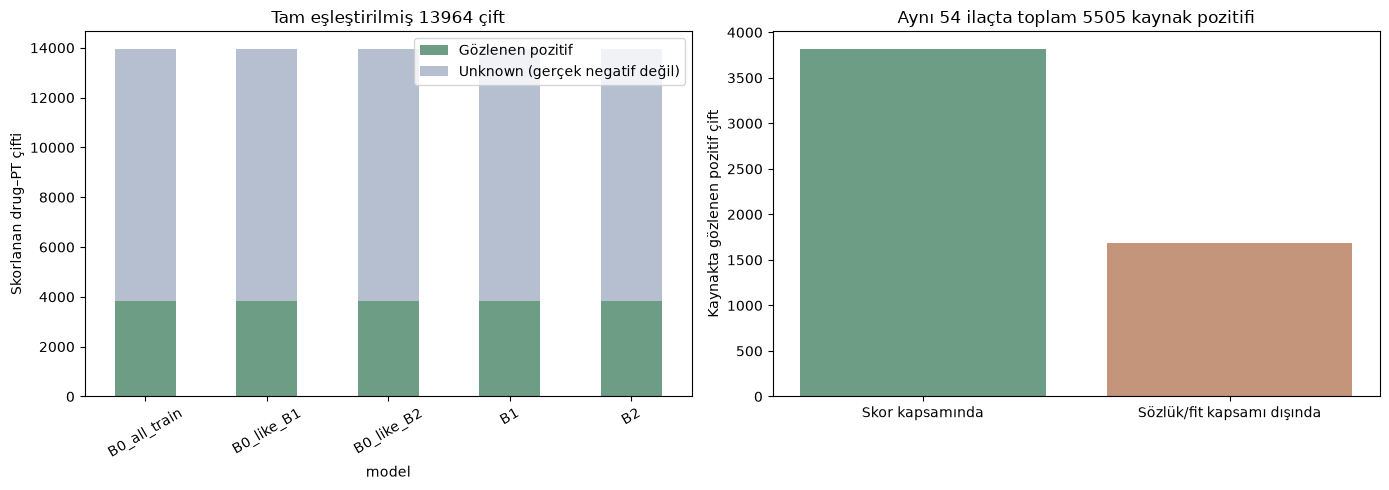

In [6]:
common=coverage[coverage.protocol.eq('primary')&coverage.scope.eq('paired54')];display(common.drop(columns=['semantics']))
fig,axs=plt.subplots(1,2,figsize=(14,5));c=common.set_index('model').loc[order]
pd.DataFrame({'Gözlenen pozitif':c.observed_positive_scored,'Unknown (gerçek negatif değil)':c.unknown_scored_NOT_verified_negative}).plot.bar(stacked=True,ax=axs[0],color=['#6e9d86','#b5bfd0']);axs[0].set(ylabel='Skorlanan drug–PT çifti',title='Tam eşleştirilmiş 13964 çift')
axs[1].bar(['Skor kapsamında','Sözlük/fit kapsamı dışında'],[3820,1685],color=['#6e9d86','#c4947b']);axs[1].set(ylabel='Kaynakta gözlenen pozitif çift',title='Aynı 54 ilaçta toplam 5505 kaynak pozitifi')
axs[0].tick_params(axis='x',rotation=30);plt.tight_layout();plt.savefig(FIG/'05_positive_unknown_and_uncovered.png',dpi=160);plt.show()

**Yorum:** Ortak kapsamda her yöntem 54 ilaç/13964 çift üzerinde karşılaştırıldı: 3820 gözlenen pozitif, 10144 unknown. Aynı ilaçlarda 1685 ek kaynak pozitifi folda özgü seçilmiş/fit edilmiş hedeflerin dışındadır. Bu 1685, bütün 62 kohorttaki toplam eksik etiket sayısı değildir. Değerlendirilen uzay dışındaki pozitiflere başarısızlık/negatif etiketi uydurulmadı; kapsam raporlandı. Dolayısıyla 0,65 civarı AP, tüm 1061 PT ve 62 ilaçta tam hedef uzayı performansı iddiası taşımaz. B0'nın tüm-62 referansı da yine sabit cohort-train hedef sözlüğüne koşulludur.

## 6. Koruma, bilimsel sonuç ve açık ROADMAP görevleri

In [7]:
display(read('ROADMAP_WP08_remaining_tasks.csv'))
done=json.loads((QA/'evaluation_complete.json').read_text(encoding='utf-8'));display(pd.DataFrame([done]))
import plotly.graph_objects as go
f=read('per_drug_model_minus_matched_frequency.csv');f=f[f.protocol.eq('primary')]
fig=go.Figure()
for model in ['B1','B2']:
    a=f[f.model.eq(model)];fig.add_trace(go.Scatter(x=a.drug_id,y=a.AP_difference,mode='markers',name=model,hovertemplate='%{x}<br>Model − eşleştirilmiş B0 AP=%{y:.3f}<extra>'+model+'</extra>'))
fig.add_hline(y=0,line_dash='dash');fig.update_layout(title='Keşifsel drug-AP farkları • klinik risk değil',height=650,width=1200,xaxis_title='DrugBank ID',yaxis_title='Observed-record AP farkı')
fig.write_html(FIG/'per_drug_frequency_reference_interactive.html',include_plotlyjs=True,full_html=True)

,task,status,scope_note
0,Drug-disjoint / nested split / train-only scaler,"Tamamlandı, v1 kilitli",Bu ekte değişmedi; B0 farklı seed veya split aramadı
1,Observed-record LR ve koşullu grup CI / leakage test,İlk B1/B2 ve keşifsel B0 tamamlandı,Sabit OOF CI tüm tekrar-eğitim belirsizliği değil
2,5 kimya + ATC baseline varyantı,Yapılmadı; kullanıcı onayı bekler,"WP02 kaynak kodları, train-only/sabit hiyerarşi kararı; eski one-hot kullanılmaz"
3,RF ve kimya MLP baseline,Yapılmadı; ilk eğitim onayı bunları dışladı,Kapasite/arama planı sonuç görmeden ayrı sürümlenmeli; bu ekte başlatılmadı
4,Protein-mean MLP baseline,Yapılmadı,"Mevcut B2 rol özetli LR, MLP veya PPI/GiG değildir"
5,Gerçek PU loss / class-prior varsayım deneyi,Ayrı yöntem seçilmedi; mevcut hedef observed-record proxy,WP08 karşılaştırmalı PU öğretimi var; ek PU modeli zorunluymuş gibi otomatik eklenmez
6,Tarihsel V6 metriklerinin bağımsız doğrulanması,Doğrulandı iddiası yok,Bu 62/PT/clean giriş deneyleri eski 38/30/sızıntılı sistemi yeniden doğrulamaz
7,WP08 nihai kapsam/kapanış kararı,Açık; kullanıcı onayı bekleniyor,Yapılmayan roadmap varyantları için yap/ertele/kapsam daralt kararı gerekir
8,PPI encoder gerçek forward ve ablation,"WP09 görevi, başlamadı",WP08 eksiğini kapatmak için kendiliğinden WP09a geçilmez


,version,policy_sha256,frequency_sha256_unchanged,query_scores_sha256_unchanged,B1_B2_score_file_sha256_unchanged,selected_C_sha256_unchanged,group_bootstrap_reps,elapsed_seconds,semantics,exploratory_after_B1_B2_results,no_B1_B2_refit_or_retuning,WP08_closed,WP09_started
0,B0_frequency_reference_v1,3a3b9139f2175b53e54aa818eeb5fcd8f315499c3eb6f83fd51956046dbd06ab,a71d3662bf269cc3610a7630dad7c7c802768f82c06854ae5d4341c9c18bdef7,49c525865d3883f75b1fd566de3fa1751ce87df2082ab8bd2573647b0a7c9c30,e4b8be02329ce0f6b5cb78083a6426cde12336fe7979718951f293a12cff77aa,5e20e8df3aa05d2a74cf67eb3abae565fe13fd6ad339eefebe6800ac431ff2c6,1000,120.846767,Exploratory train-frequency observed-record ranking reference; unknown is NOT verified negative;...,True,True,False,False


**Kapanış:** B1/B2 v1 ve tüm eski QA korunur. B0 frekansları test etiketi/değeriyle ayarlanmadı; sonuç görüldükten sonra smoothing/model/split/seed seçilmedi. Bu ek, B1/B2'den sonra kararlaştırılan keşifsel referanstır. ATC, RF/MLP, protein-mean MLP gibi yol haritasındaki yapılmamış varyantlar tabloda açık bırakıldı; gerçek PPI encoder ve ablation WP09'dur, bu ekte başlanmaz.

[Bilimsel B0 raporu](../reports/WP08_B0_FREQUENCY_REFERENCE.md). WP08 kapanmadı; sonuç ve sonraki kapsam için kullanıcı onayı beklenir. Bütün ölçüler observed-record proxy'dir; unknown gerçek negatif değildir.